# Round 1 starter: tabular classification in 2 hours

**How to use it on the day:** copy this file, fill in the `CONFIG` cell, then *Run All*. Every section prints something you can say out loud to the team.
Timeline: frame (0–15) → split roles (15–30) → build (30–90, checks at 60/90) → consolidate (90–110) → present (110–120).
Regression or time series? See the swap notes at the bottom.

## 0 · Framing (fill in during the first 10 minutes, agreed as a team)
- **Business goal:**
- **Decision the model supports (who acts, and when):**
- **Prediction point / horizon (what is known at that moment?):**
- **Target (exact definition):**
- **Success metric (and why, given the cost of FP vs FN):**
- **Assumptions we're making (say them out loud):**

In [1]:
# ---- CONFIG: edit this cell only ----
DATA_PATH = "test.csv"          # or a .db file with SQL_QUERY below
SQL_QUERY = None                # e.g. "SELECT * FROM bookings"
TARGET = "target"               # target column name
POSITIVE = None                 # label of the positive class if not already 0/1, e.g. "Yes"
DROP_COLS = []                  # IDs, free text, and anything recorded AFTER the prediction point
TIME_COL = None                 # set this to split by time instead of randomly
COST_FP, COST_FN = 1.0, 5.0     # rough business costs; used for threshold choice
RANDOM_STATE = 42

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
pd.set_option("display.max_columns", 50)

In [3]:
# 1 · Load
if SQL_QUERY:
    import sqlite3
    df = pd.read_sql(SQL_QUERY, sqlite3.connect(DATA_PATH))
else:
    df = pd.read_csv(DATA_PATH)

# Text columns that are really numbers (e.g. blanks stored as " ") -> numeric
for c in df.columns.drop(TARGET):
    if not pd.api.types.is_numeric_dtype(df[c]):
        conv = pd.to_numeric(df[c], errors="coerce")
        if conv.notna().mean() > 0.95:
            print(f"coerced {c} to numeric ({df[c].notna().sum() - conv.notna().sum()} unparseable -> NaN)")
            df[c] = conv

if POSITIVE is not None:
    df[TARGET] = (df[TARGET] == POSITIVE).astype(int)
print(df.shape)
df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
# 2 · Quick EDA: say the base rate out loud
print("base rate:", round(df[TARGET].mean(), 4), "| rows:", len(df))
print("\nmissing (top 10):"); print(df.isna().mean().sort_values(ascending=False).head(10).round(3))
print("\nduplicates:", df.duplicated().sum())
df.describe(include="all").T.head(30)

base rate: 0.6274 | rows: 569

missing (top 10):
mean radius               0.0
mean texture              0.0
mean perimeter            0.0
mean area                 0.0
mean smoothness           0.0
mean compactness          0.0
mean concavity            0.0
mean concave points       0.0
mean symmetry             0.0
mean fractal dimension    0.0
dtype: float64

duplicates: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [5]:
# 3 · Leakage and ID audit: anything that (almost) perfectly separates the target?
suspects = []
for c in df.columns.drop(TARGET):
    n = df[c].nunique()
    if n > 0.9 * len(df) and not pd.api.types.is_float_dtype(df[c]):
        suspects.append((c, "ID-like (unique per row)"))
        continue
    if n <= 50:
        g = df.groupby(c)[TARGET].agg(["mean", "size"])
        g = g[g["size"] >= 30]
        if ((g["mean"] <= 0.005) | (g["mean"] >= 0.995)).any():
            suspects.append((c, "a category with ~0% or ~100% target rate"))
    elif pd.api.types.is_numeric_dtype(df[c]):
        s = df[c].fillna(df[c].median())
        auc = roc_auc_score(df[TARGET], s)
        if max(auc, 1 - auc) > 0.95:
            suspects.append((c, f"single-feature AUC {max(auc, 1 - auc):.3f}"))
for c, why in suspects:
    print(f"CHECK {c}: {why}  -> when is this recorded relative to the prediction point?")
if not suspects:
    print("no obvious leakage flags (still reason about timing for each feature)")

CHECK mean concave points: single-feature AUC 0.964  -> when is this recorded relative to the prediction point?
CHECK worst radius: single-feature AUC 0.970  -> when is this recorded relative to the prediction point?
CHECK worst perimeter: single-feature AUC 0.975  -> when is this recorded relative to the prediction point?
CHECK worst area: single-feature AUC 0.970  -> when is this recorded relative to the prediction point?
CHECK worst concave points: single-feature AUC 0.967  -> when is this recorded relative to the prediction point?


In [6]:
# 4 · Split: decide deliberately (random stratified / temporal / grouped)
data = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
if TIME_COL:
    data = data.sort_values(TIME_COL)
    cut = int(len(data) * 0.8)
    train, test = data.iloc[:cut], data.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=4)
    X_tr, X_te = train.drop(columns=[TARGET, TIME_COL]), test.drop(columns=[TARGET, TIME_COL])
else:
    train, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
    cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    X_tr, X_te = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])
y_tr, y_te = train[TARGET], test[TARGET]
print("train", X_tr.shape, "base", round(y_tr.mean(), 3), "| test", X_te.shape, "base", round(y_te.mean(), 3))

train (455, 30) base 0.626 | test (114, 30) base 0.632


In [7]:
# 5 · Preprocess (inside the Pipeline, so nothing leaks across folds) + compare models
num = X_tr.select_dtypes("number").columns.tolist()
cat = X_tr.select_dtypes(exclude="number").columns.tolist()
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01))]), cat)])
models = {
    "dummy":  DummyClassifier(strategy="prior"),
    "logreg": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "rf":     RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "hgb":    HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = []
for name, m in models.items():
    r = cross_validate(Pipeline([("pre", pre), ("clf", m)]), X_tr, y_tr, cv=cv,
                       scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    rows.append({"model": name, "PR-AUC": r["test_pr_auc"].mean(), "±": r["test_pr_auc"].std(),
                 "ROC-AUC": r["test_roc_auc"].mean(), "fit s": r["fit_time"].mean()})
res = pd.DataFrame(rows).set_index("model").round(3).sort_values("PR-AUC", ascending=False)
res   # PR-AUC baseline = base rate. Is the gain over logreg worth the complexity?

,PR-AUC,±,ROC-AUC,fit s
model,,,,
logreg,0.997,0.004,0.996,0.098
hgb,0.997,0.002,0.994,0.153
rf,0.993,0.005,0.989,0.387
dummy,0.626,0.000,0.500,0.108


logreg: test PR-AUC 0.997 (base 0.632) | ROC-AUC 0.995


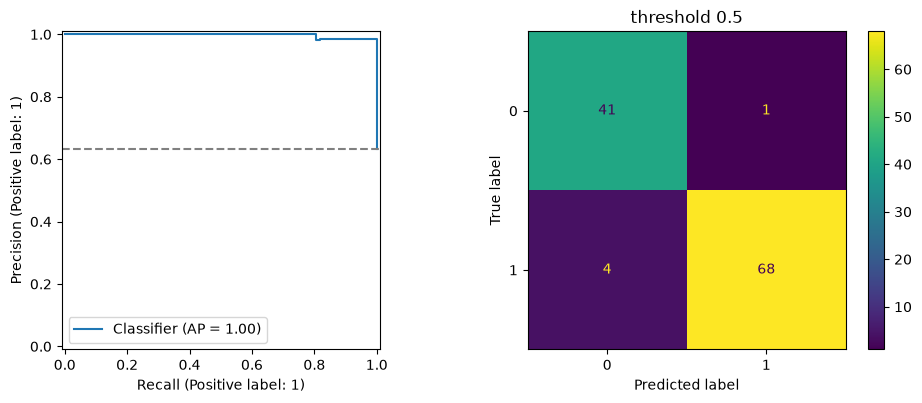

In [8]:
# 6 · Fit the chosen model once and touch the test set ONCE
BEST = res.index[0] if res.index[0] != "dummy" else res.index[1]   # or pick deliberately, e.g. "logreg"
final = Pipeline([("pre", pre), ("clf", models[BEST])]).fit(X_tr, y_tr)
p = final.predict_proba(X_te)[:, 1]
print(f"{BEST}: test PR-AUC {average_precision_score(y_te, p):.3f} (base {y_te.mean():.3f}) | ROC-AUC {roc_auc_score(y_te, p):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
PrecisionRecallDisplay.from_predictions(y_te, p, ax=ax[0]); ax[0].axhline(y_te.mean(), ls="--", c="grey")
ConfusionMatrixDisplay.from_predictions(y_te, (p >= 0.5).astype(int), ax=ax[1]); ax[1].set_title("threshold 0.5")
plt.tight_layout(); plt.show()

In [9]:
# 7 · Threshold from business cost, chosen on TRAINING predictions (never on the test set)
from sklearn.model_selection import cross_val_predict
pipe = Pipeline([("pre", pre), ("clf", models[BEST])])
if TIME_COL:   # last 20% of the training period acts as validation
    cut2 = int(len(X_tr) * 0.8)
    p_val = pipe.fit(X_tr.iloc[:cut2], y_tr.iloc[:cut2]).predict_proba(X_tr.iloc[cut2:])[:, 1]
    y_val = y_tr.iloc[cut2:]
else:          # out-of-fold probabilities on the training set
    p_val = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    y_val = y_tr
ths = np.linspace(0.05, 0.95, 19)
cost = [COST_FP * ((p_val >= t) & (y_val == 0)).sum() + COST_FN * ((p_val < t) & (y_val == 1)).sum() for t in ths]
t_best = ths[int(np.argmin(cost))]
print(f"threshold ≈ {t_best:.2f} for FP:FN cost {COST_FP}:{COST_FN} (chosen on train), applied to test:")
print(classification_report(y_te, (p >= t_best).astype(int), digits=3))

threshold ≈ 0.15 for FP:FN cost 1.0:5.0 (chosen on train), applied to test:
              precision    recall  f1-score   support

           0      1.000     0.952     0.976        42
           1      0.973     1.000     0.986        72

    accuracy                          0.982       114
   macro avg      0.986     0.976     0.981       114
weighted avg      0.983     0.982     0.982       114



In [10]:
# 8 · What drives it? (permutation importance on the test set, raw columns)
imp = permutation_importance(final, X_te, y_te, scoring="average_precision", n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=X_te.columns).sort_values(ascending=False).head(10).round(4)

worst texture           0.0027
worst concave points    0.0026
worst smoothness        0.0021
radius error            0.0021
worst area              0.0020
worst radius            0.0019
area error              0.0019
mean concave points     0.0017
worst symmetry          0.0013
worst perimeter         0.0012
dtype: float64

## Swaps for other problem types
- **Regression:** `HistGradientBoostingRegressor`, `DummyRegressor`, `Ridge`; `KFold(5, shuffle=True)`; scoring `neg_mean_absolute_error` and `neg_root_mean_squared_error`; no stratify.
- **Time series:** set `TIME_COL`; build lag/rolling features with `groupby(...).shift(1)` **before** rolling, so a row never sees its own target; `TimeSeriesSplit`.
- **Text:** `TfidfVectorizer(min_df=2, ngram_range=(1,2))` + `LogisticRegression` as the baseline, inside the Pipeline.
- **Grouped rows (same customer many times):** `GroupKFold` / `GroupShuffleSplit` on the ID.

## 5-minute presentation skeleton
1. Problem as framed: goal, decision, target, metric, and why.
2. Data: base rate, the issues we found (leakage, missing values, imbalance) and what we did about them.
3. Approach: split choice, baseline vs models, CV results table.
4. Result: test metric vs baseline, chosen threshold and its business meaning, top drivers.
5. Limitations and next steps: what we'd do with another week.